# Error compounding over generation steps

The 21 LOB-Bench scores are marginals pooled over a whole generated stream. A
model that starts close to the real prefix it was given and drifts away from it
reports the average of the two, and the pooled number cannot say which it was.
`--divergence` keeps the time index instead: the stream is cut into consecutive
windows of *h* messages and each window is scored against the whole real
distribution.

Everything below reads `docs/evidence/lobbench_divergence_mamba3_seed42.json`, written by
`run/benchmarking/run_lobbench.py`. No distance is recomputed here.

In [1]:
import io, json, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

EV = pathlib.Path("docs/evidence/lobbench_divergence_mamba3_seed42.json")
if not EV.exists():
    EV = pathlib.Path(__file__).resolve().parents[2] / "docs/evidence/lobbench_divergence_mamba3_seed42.json" if "__file__" in dir() \
        else pathlib.Path("..") / ".." / "docs/evidence/lobbench_divergence_mamba3_seed42.json"
E = json.loads(EV.read_text())

D, POOL, LAG = E["divergence"], E["pooled"], E["time_lagged"]
H          = D["horizon_length"]
X          = D["horizon_axis_messages"]
CURVE      = D["feature_curves"]
CI         = D["feature_curve_ci"]
MEAN       = D["mean_curves"]
FEATURES   = list(CURVE)
DISTANCES  = ("wasserstein", "ks", "l1")
INK, WARN  = "#1f4e79", "#c05a00"

plt.rcParams.update({"figure.dpi": 300, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
plt.ioff()

def show(fig):
    """Render a figure as a 256-colour palette PNG.

    Outputs are committed so the notebook renders inline on GitHub, and that
    only helps if the file stays small enough to render. Flat-colour charts
    quantise without visible loss and the file lands around a third of the
    size. This lives here rather than in a post-processing step because a
    post-processing step is undone by the next `nbconvert --execute`.
    """
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    try:
        from PIL import Image as _PIL
        im = _PIL.open(buf).convert("RGB").quantize(colors=256)
        out = io.BytesIO(); im.save(out, format="PNG", optimize=True)
        display(Image(data=out.getvalue()))
    except ImportError:
        display(Image(data=buf.getvalue()))

# The curve covers the scores that produced windows; the pooled reference must
# be the mean over exactly those, not the published 21-score mean, or the line
# and the curve would be averages of different things.
POOLED_LIKE = {d: float(np.mean([POOL["feature_scores"][f][d] for f in FEATURES]))
               for d in DISTANCES}
DROPPED = D["scores_without_windows"]

print(f"{len(FEATURES)} scores x {D['n_horizons']} windows of {H} generated messages")
print(f"{E['inference']['sequences']} sequences, {E['inference']['model']}")
if DROPPED:
    print(f"no window at h={H}: {', '.join(DROPPED)} "
          f"(eval.orderflow_imbalance is a 100-message rolling mean)")

17 scores x 5 windows of 50 generated messages
3136 sequences, mamba3 seed 42, 26tok model zoo, step 30k
no window at h=50: ofi, ofi_up, ofi_stay, ofi_down (eval.orderflow_imbalance is a 100-message rolling mean)


## Figure 1 - what the pooled number is hiding

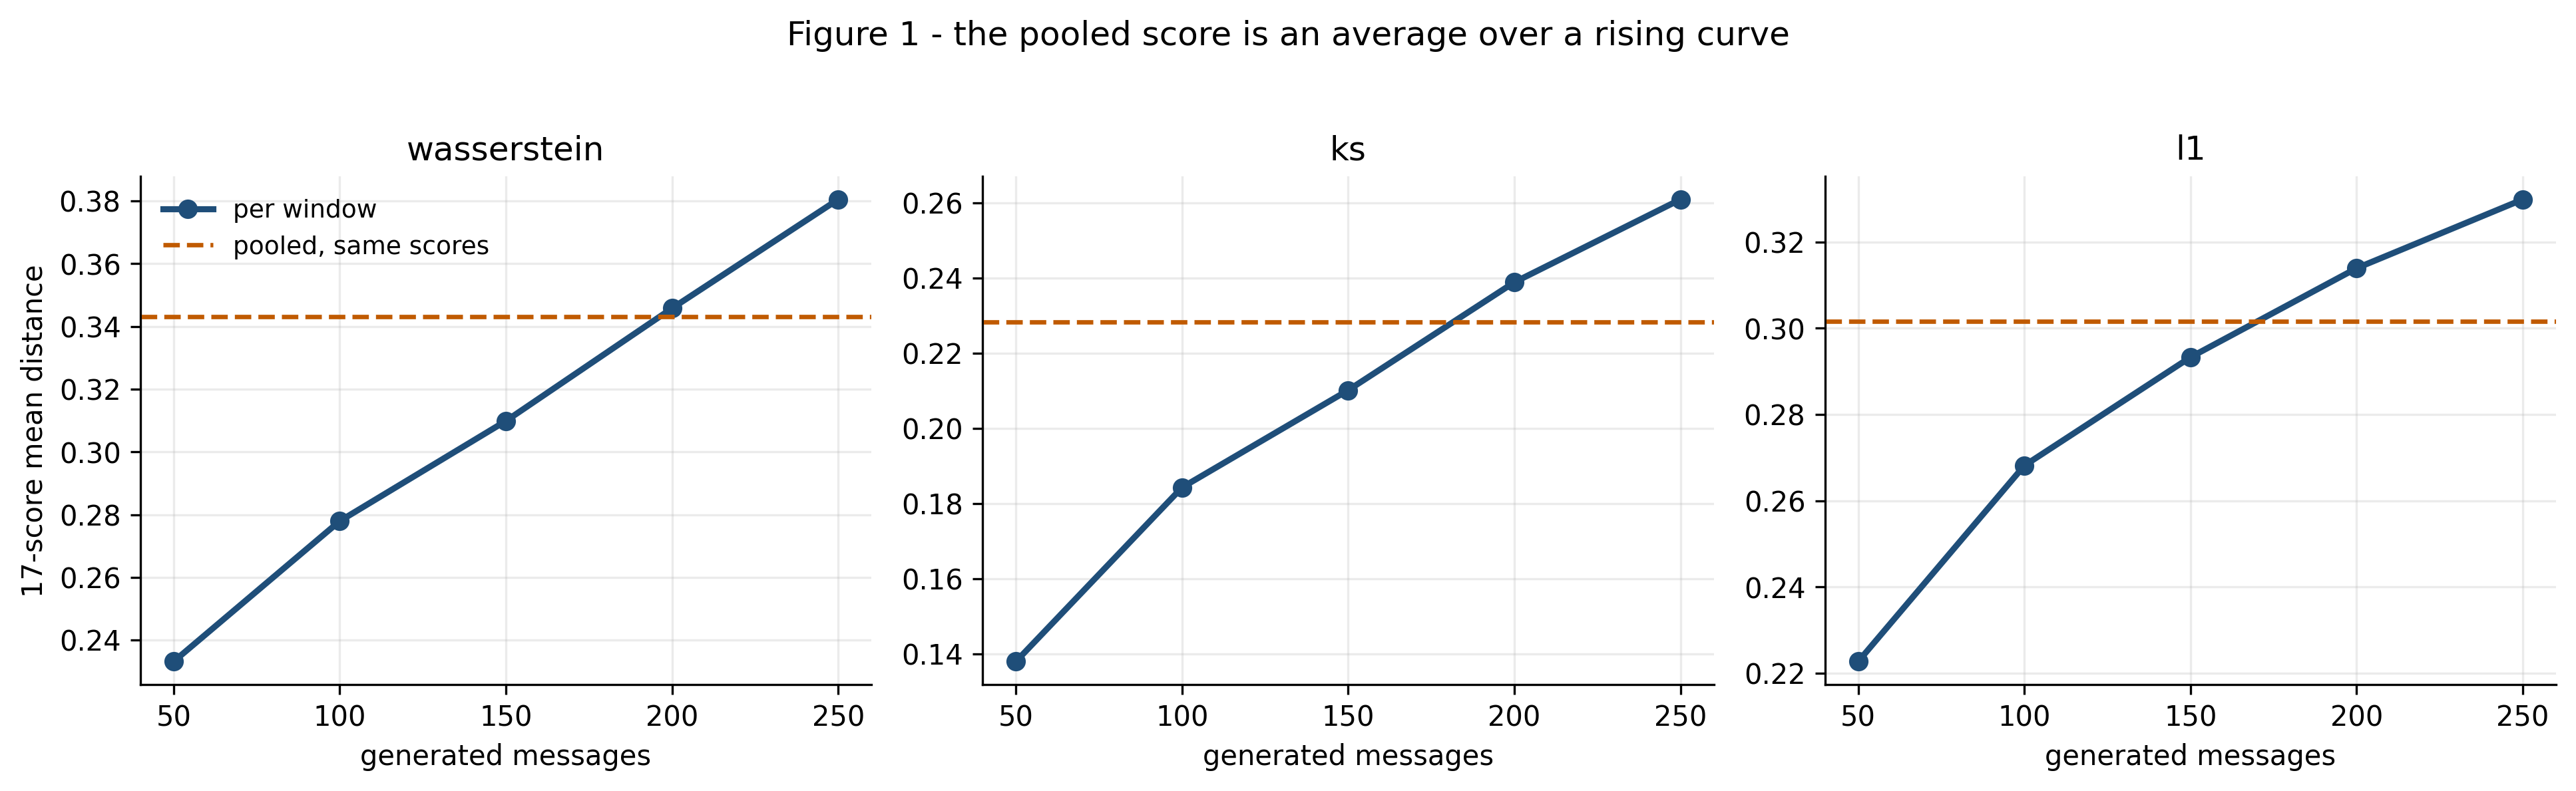

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, d in zip(axes, DISTANCES):
    ax.plot(X, MEAN[d], marker="o", lw=2.2, color=INK, label="per window")
    ax.axhline(POOLED_LIKE[d], ls="--", lw=1.6, color=WARN,
               label="pooled, same scores")
    ax.set_title(d); ax.set_xlabel("generated messages")
axes[0].set_ylabel(f"{len(FEATURES)}-score mean distance")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Figure 1 - the pooled score is an average over a rising curve", y=1.03)
fig.tight_layout(); show(fig)

*Every distance rises monotonically with position in the stream, and the pooled number sits in the middle of that rise rather than describing any part of it.*

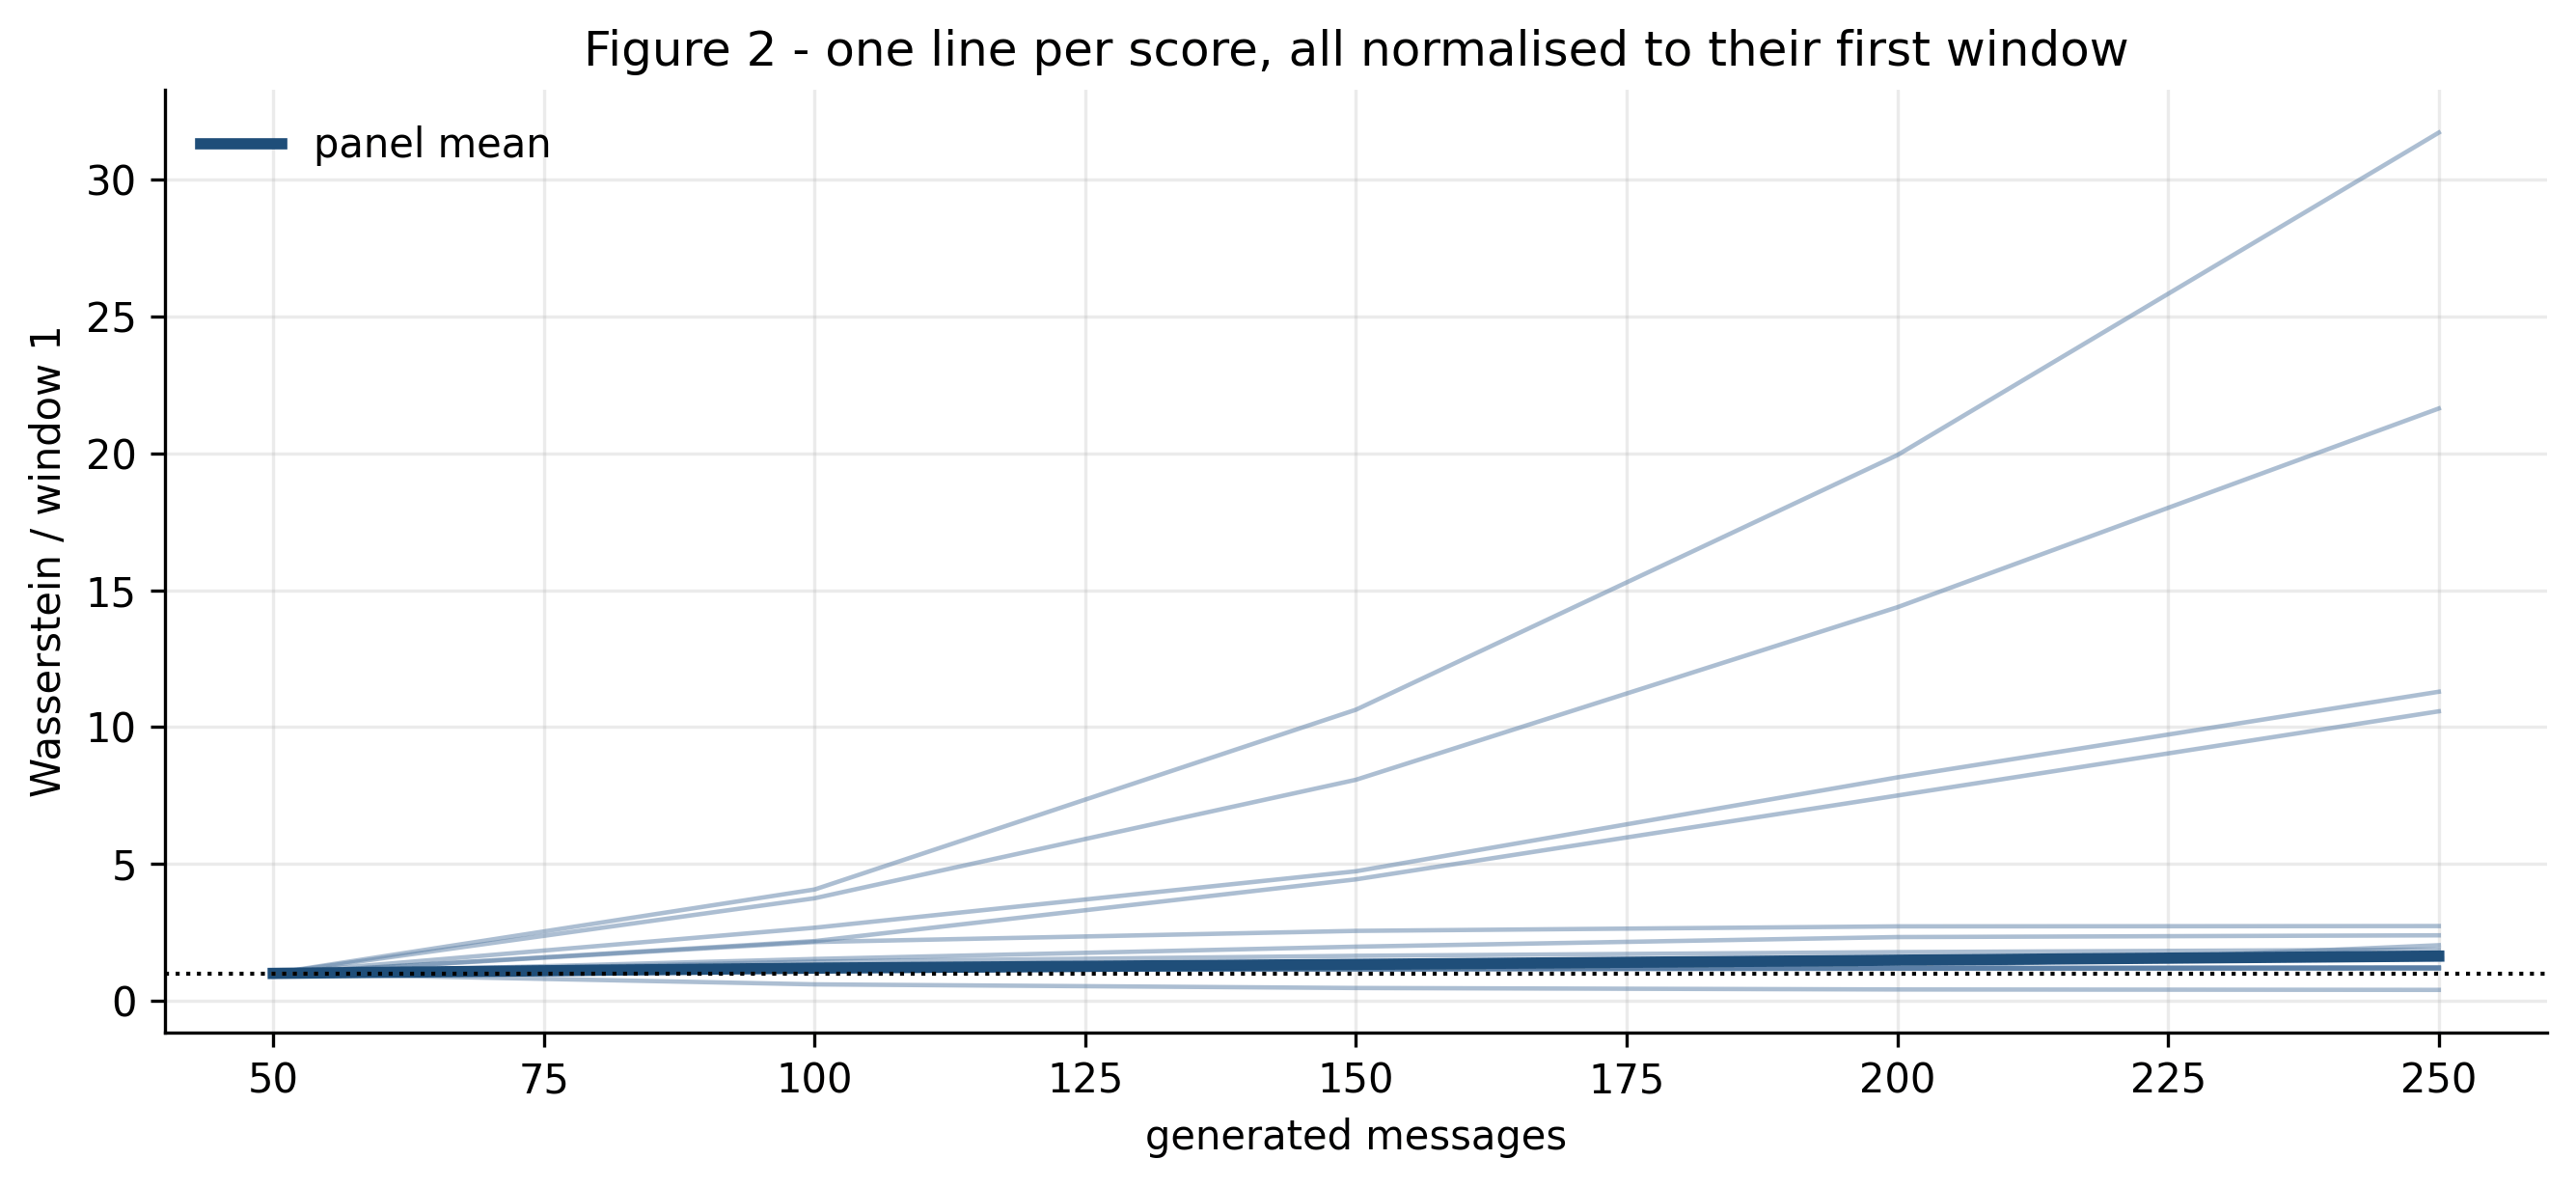

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for f in FEATURES:
    y = CURVE[f]["wasserstein"]
    if y[0]:
        ax.plot(X, [v / y[0] for v in y], lw=1.1, alpha=.5, color="#5b7fa6")
ax.plot(X, [v / MEAN["wasserstein"][0] for v in MEAN["wasserstein"]],
        lw=2.8, color=INK, label="panel mean")
ax.axhline(1, ls=":", color="k", lw=1)
ax.set_xlabel("generated messages"); ax.set_ylabel("Wasserstein / window 1")
ax.set_title("Figure 2 - one line per score, all normalised to their first window")
ax.legend(frameon=False); fig.tight_layout(); show(fig)

*The compounding belongs to the panel, not to one badly behaved score: the individual curves fan out but almost all of them point the same way.*

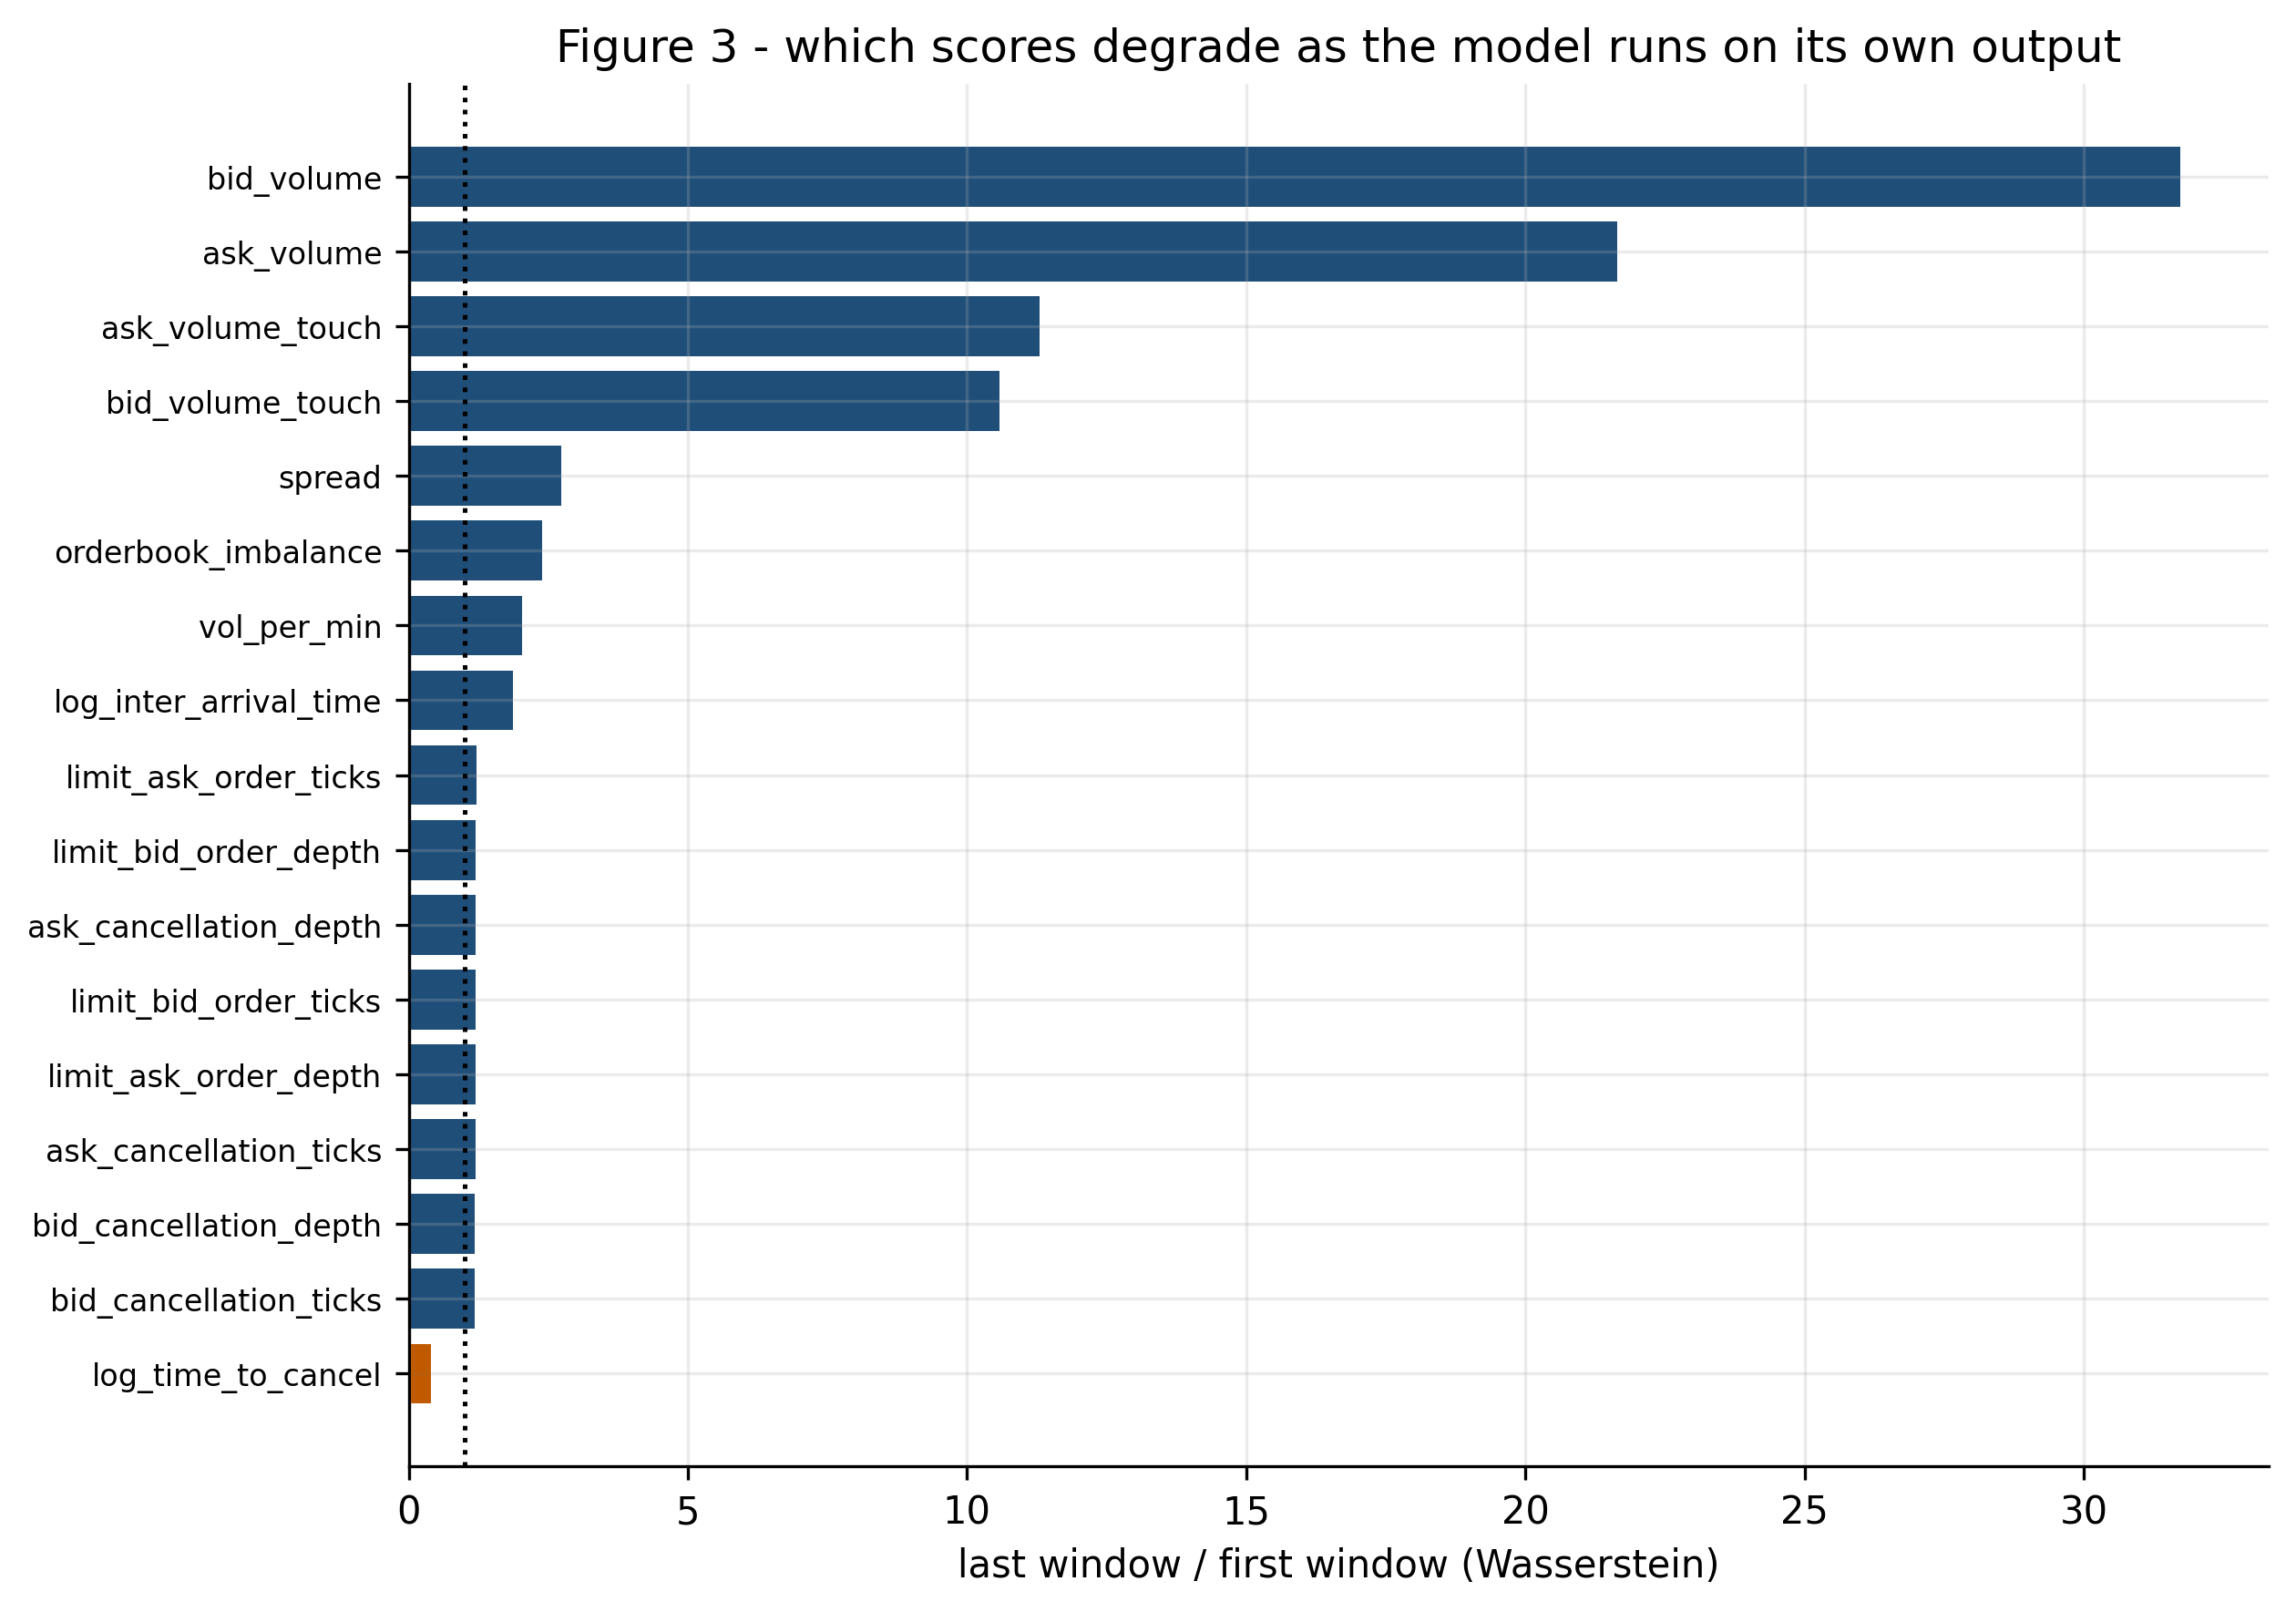

In [4]:
ratio = {f: CURVE[f]["wasserstein"][-1] / CURVE[f]["wasserstein"][0]
         for f in FEATURES if CURVE[f]["wasserstein"][0]}
order = sorted(ratio, key=ratio.get)
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(range(len(order)), [ratio[f] for f in order],
        color=[INK if ratio[f] >= 1 else WARN for f in order])
ax.axvline(1, ls=":", color="k", lw=1.2)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel("last window / first window (Wasserstein)")
ax.set_title("Figure 3 - which scores degrade as the model runs on its own output")
fig.tight_layout(); show(fig)

*Ranking the scores by how much they degrade is a question the pooled table cannot be asked at all; the worst of them more than double.*

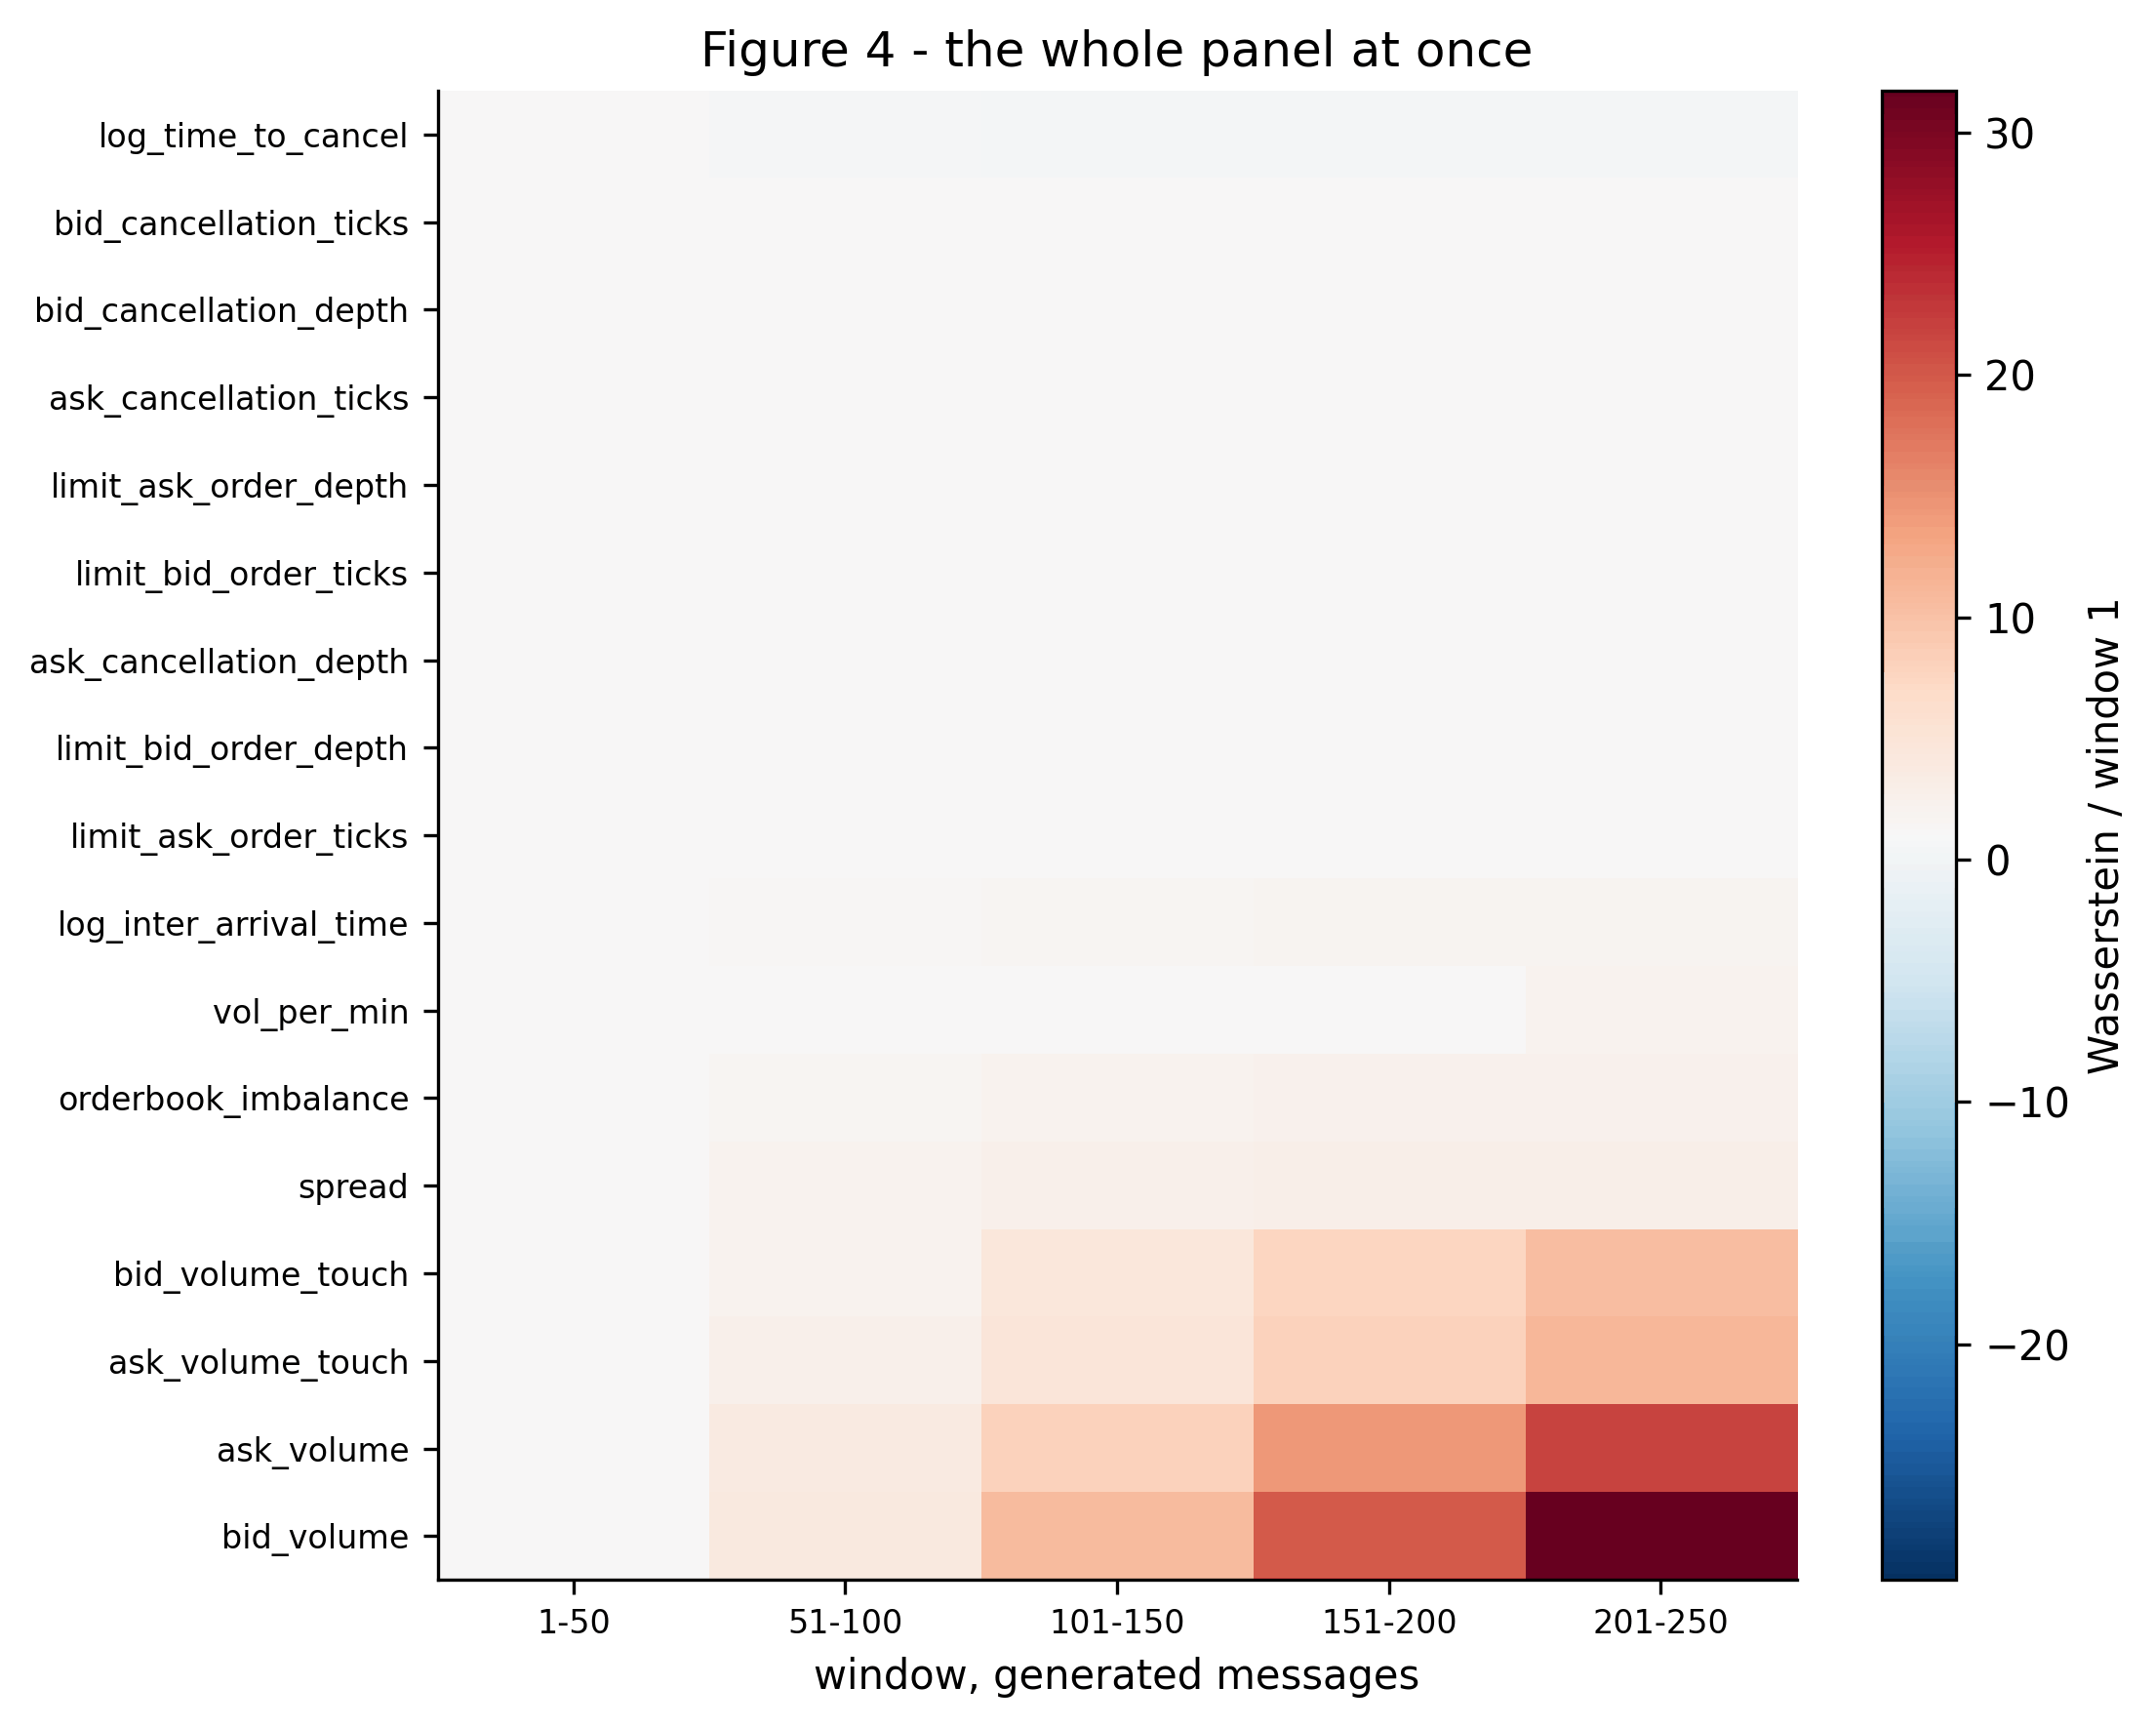

In [5]:
M = np.array([[CURVE[f]["wasserstein"][i] / CURVE[f]["wasserstein"][0]
               for i in range(len(X))] for f in order])
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(M, aspect="auto", cmap="RdBu_r",
               vmin=2 - M.max(), vmax=M.max())
ax.set_xticks(range(len(X))); ax.set_xticklabels([f"{x-H+1}-{x}" for x in X], fontsize=8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel("window, generated messages"); ax.grid(False)
fig.colorbar(im, ax=ax, label="Wasserstein / window 1")
ax.set_title("Figure 4 - the whole panel at once")
fig.tight_layout(); show(fig)

*Read across a row for one score's trajectory and down a column for the state of the panel at that point in the generation: the blue deepens to the right almost everywhere.*

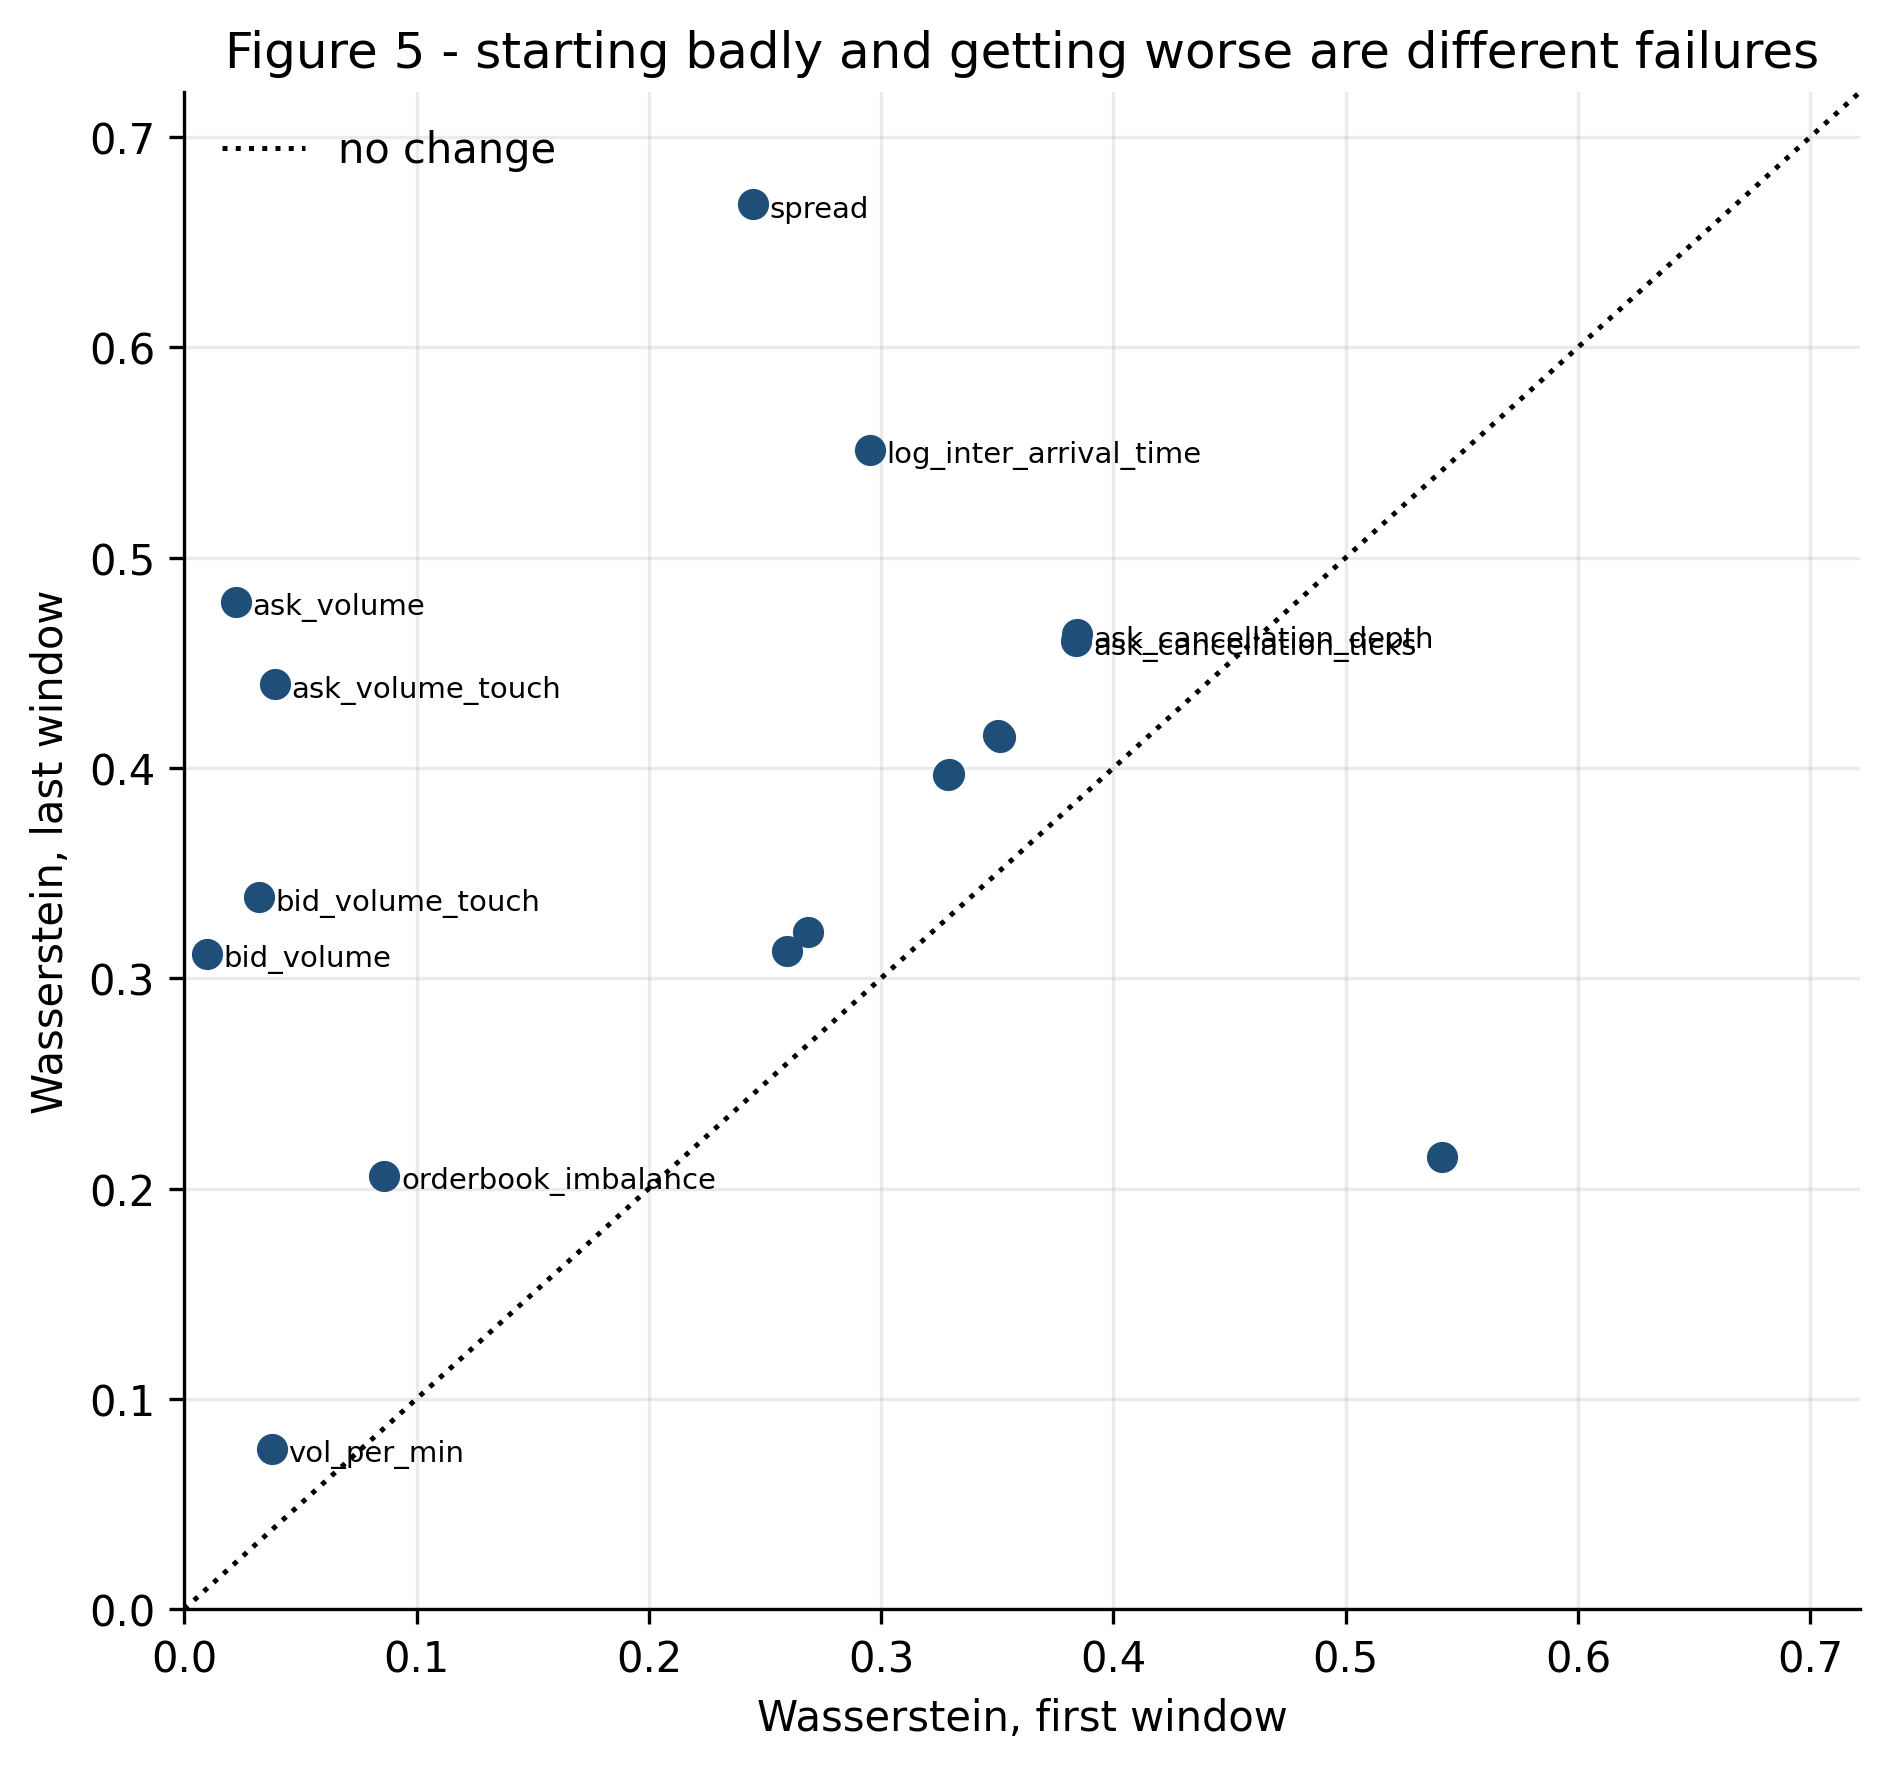

In [6]:
first = np.array([CURVE[f]["wasserstein"][0] for f in FEATURES])
last  = np.array([CURVE[f]["wasserstein"][-1] for f in FEATURES])
fig, ax = plt.subplots(figsize=(6.4, 6))
ax.scatter(first, last, s=42, color=INK, zorder=3)
lim = [0, max(first.max(), last.max()) * 1.08]
ax.plot(lim, lim, ls=":", color="k", lw=1.2, label="no change")
for f, a, b in zip(FEATURES, first, last):
    if b / max(a, 1e-9) > 2.0 or b > .45:
        ax.annotate(f, (a, b), fontsize=7, xytext=(4, -3), textcoords="offset points")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Wasserstein, first window"); ax.set_ylabel("Wasserstein, last window")
ax.set_title("Figure 5 - starting badly and getting worse are different failures")
ax.legend(frameon=False); fig.tight_layout(); show(fig)

*Points above the diagonal got worse during generation; points far to the right started badly. These are different failures and the pooled score sums them.*

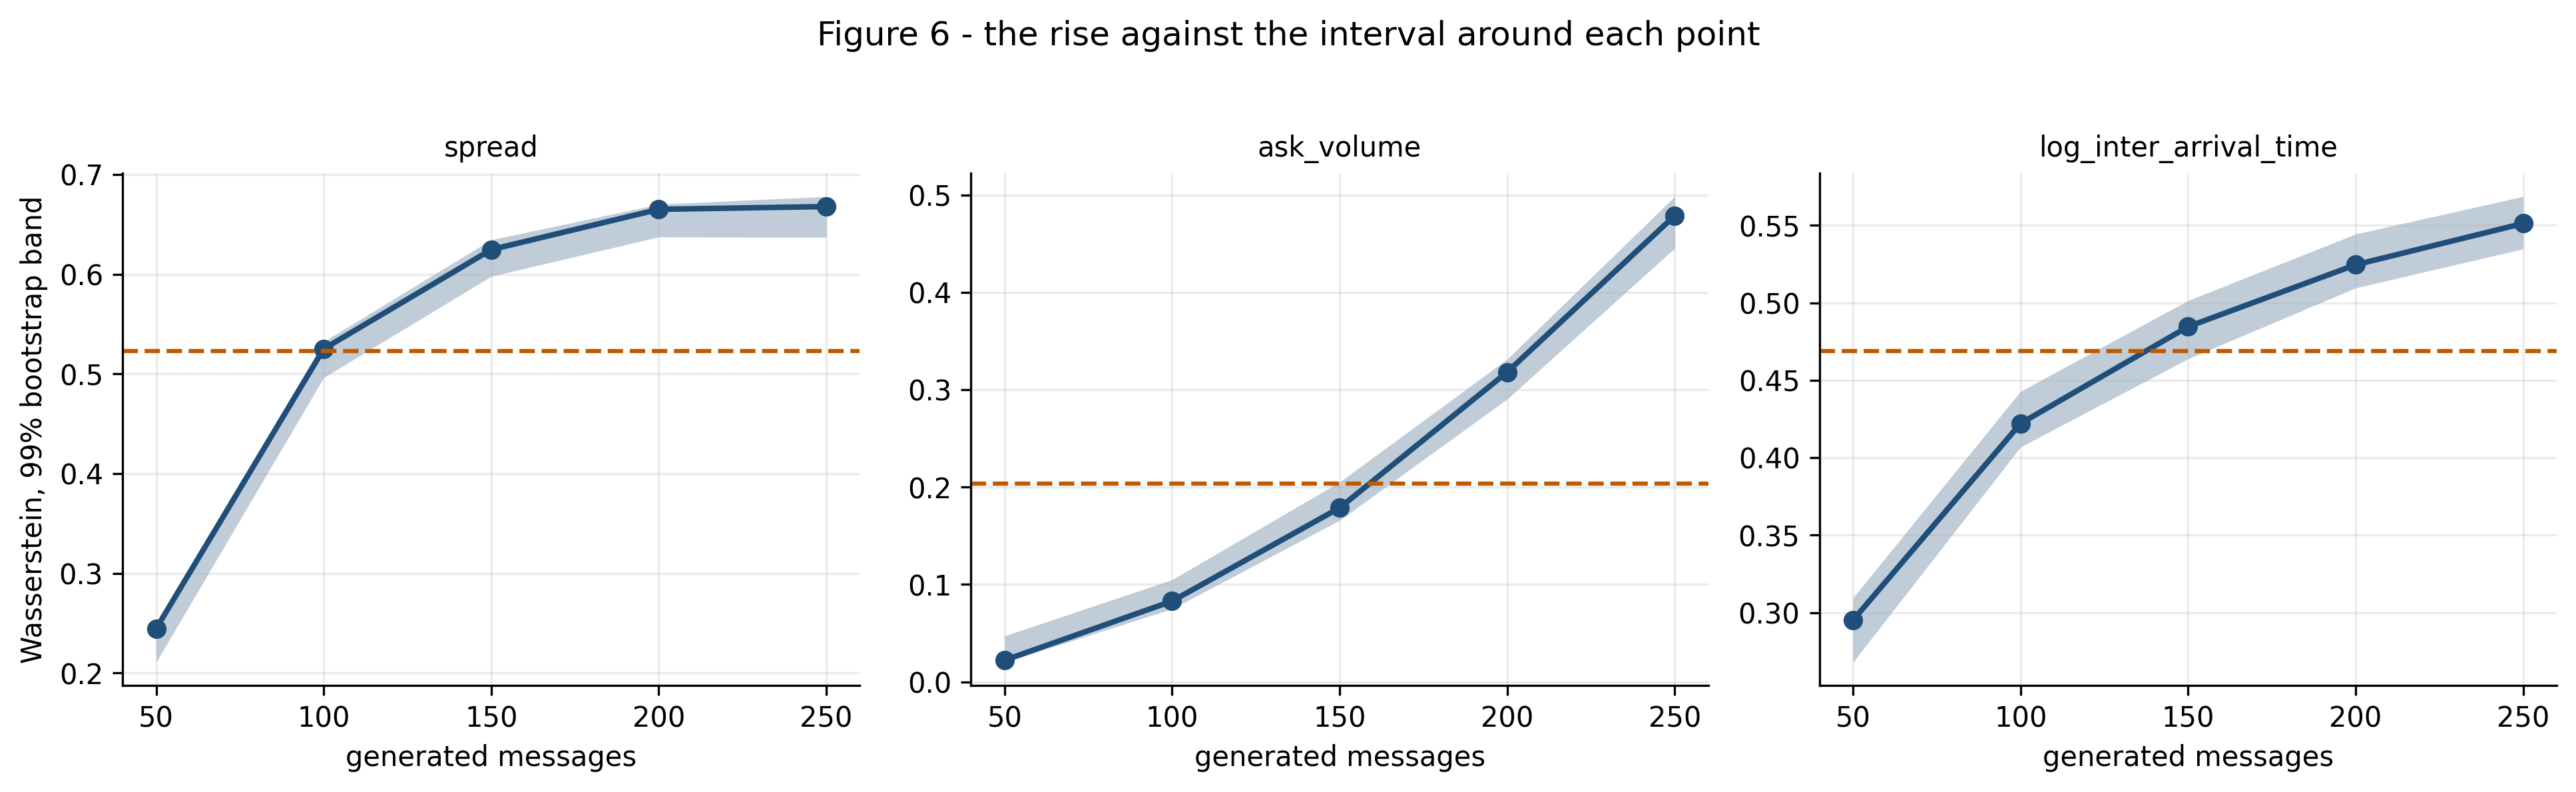

In [7]:
PICKED = ["spread", "ask_volume", "log_inter_arrival_time"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, f in zip(axes, PICKED):
    y = np.array(CURVE[f]["wasserstein"], dtype=float)
    ci = CI[f]["wasserstein"]
    lo = np.array([c[0] if c else np.nan for c in ci], dtype=float)
    hi = np.array([c[1] if c else np.nan for c in ci], dtype=float)
    ax.fill_between(X, lo, hi, alpha=.28, color=INK, lw=0)
    ax.plot(X, y, marker="o", lw=2, color=INK)
    ax.axhline(POOL["feature_scores"][f]["wasserstein"], ls="--", lw=1.5, color=WARN)
    ax.set_title(f, fontsize=10); ax.set_xlabel("generated messages")
axes[0].set_ylabel("Wasserstein, 99% bootstrap band")
fig.suptitle("Figure 6 - the rise against the interval around each point", y=1.03)
fig.tight_layout(); show(fig)

*The rise is many interval widths wide, so it is not bootstrap noise -- and the pooled value (dashed) is met somewhere in the middle of each curve. The band is a stable width but not a reproducible position: scoring this same data twice moves an endpoint by 8.8% at the median and 21.8% at the 95th percentile of the band width, because the scorer shares one generator across threads. Read it as a scale, not as a boundary.*

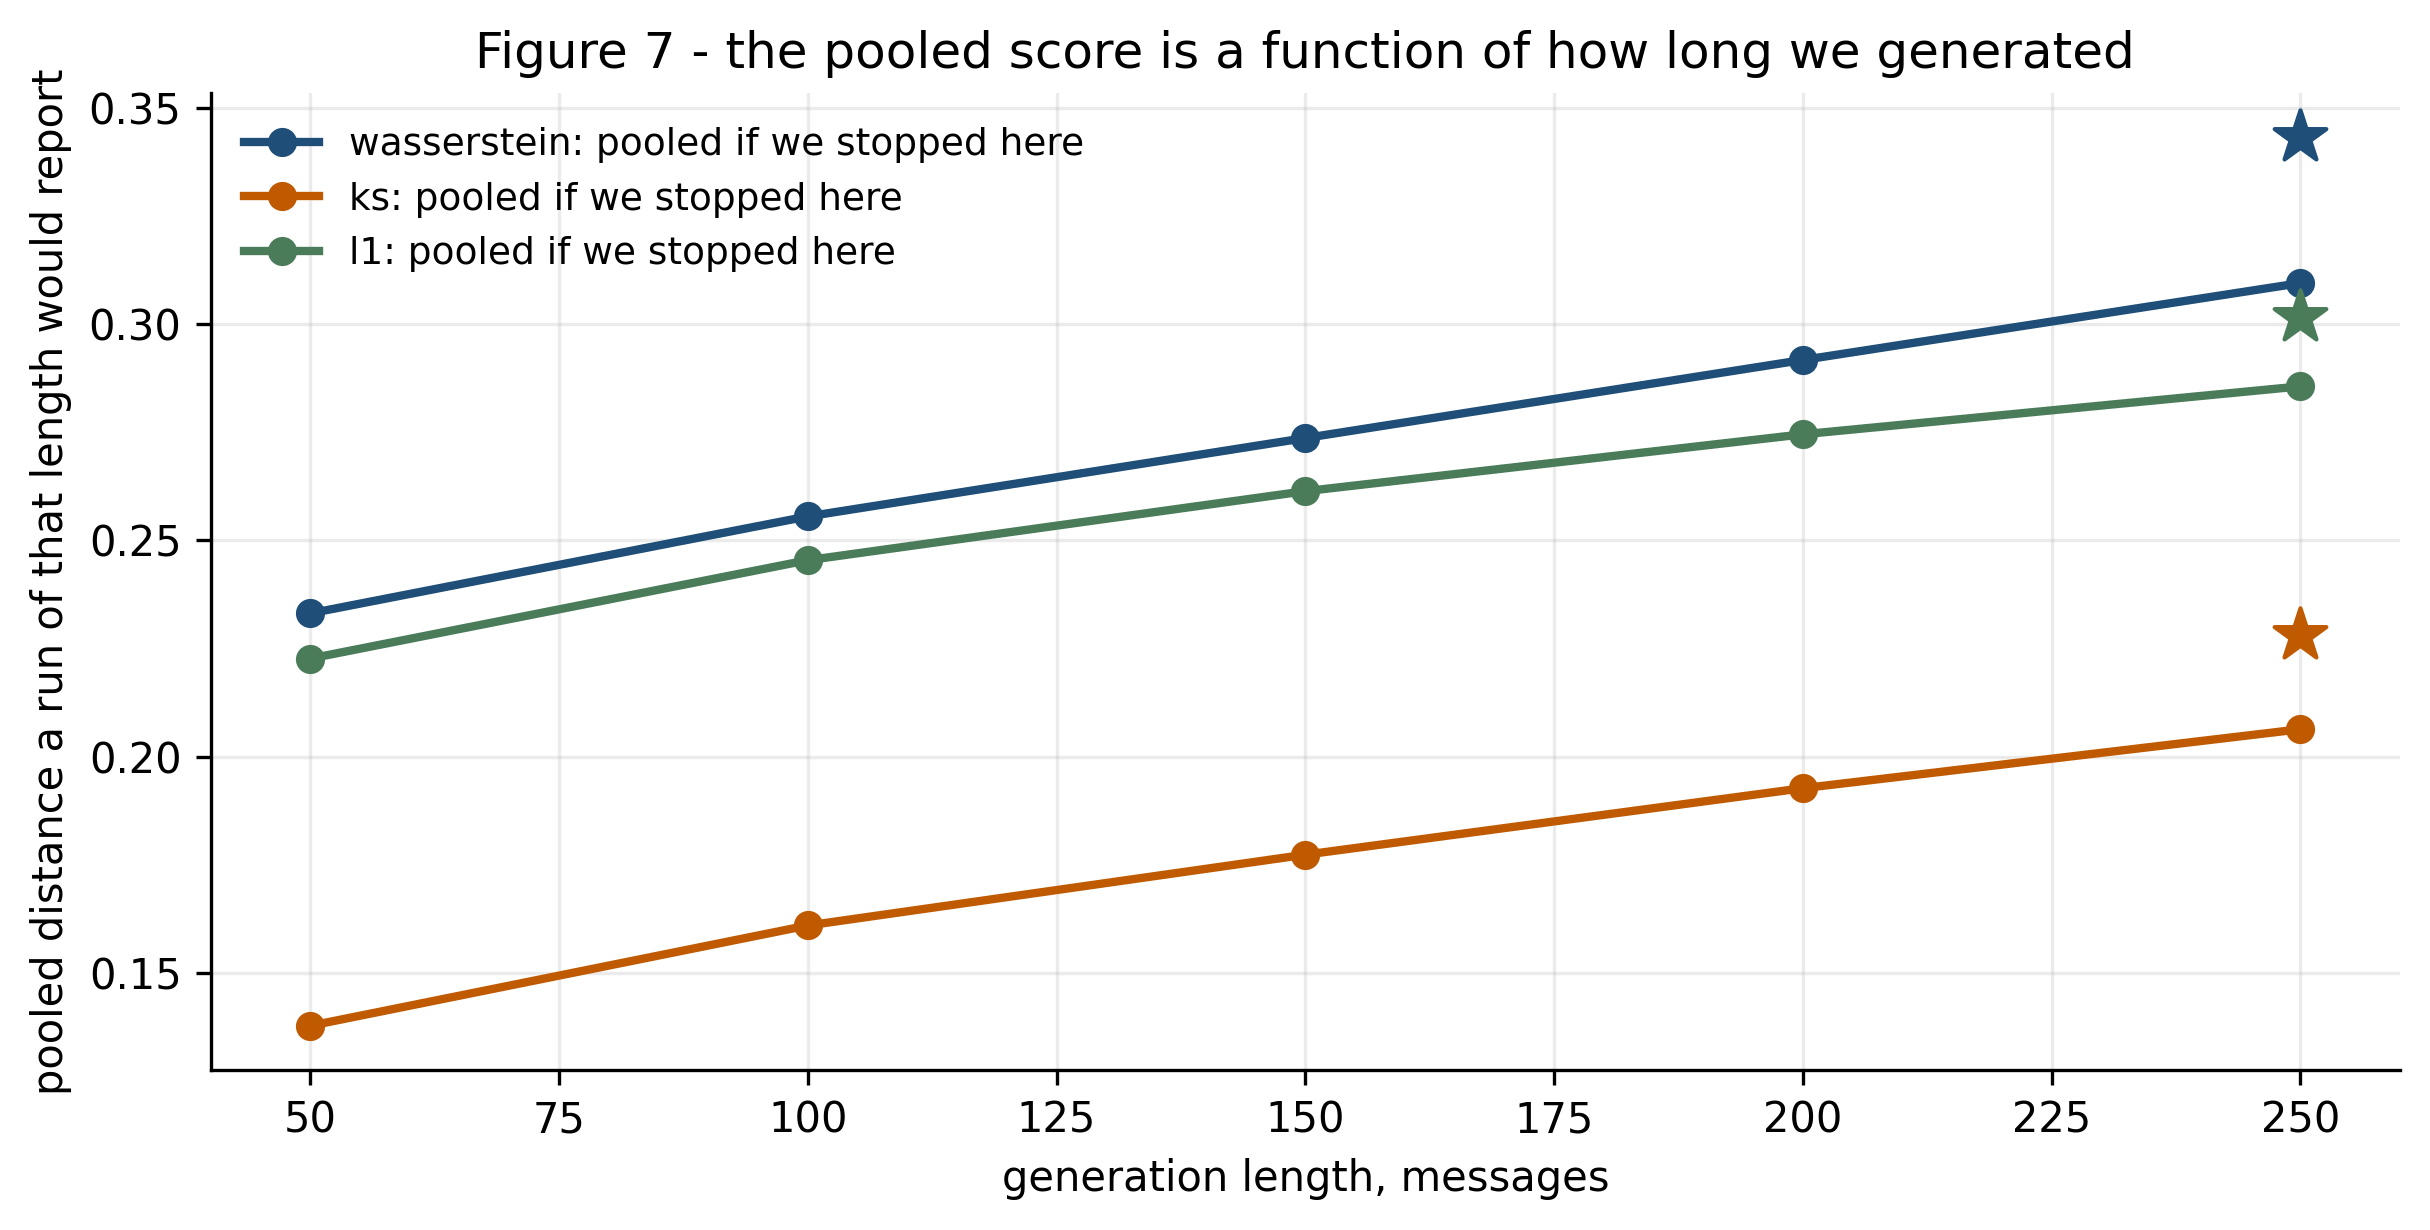

In [8]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))
for d, c in zip(DISTANCES, [INK, WARN, "#4a7c59"]):
    cum = np.cumsum(MEAN[d]) / np.arange(1, len(X) + 1)
    ax.plot(X, cum, marker="o", lw=2, color=c, label=f"{d}: pooled if we stopped here")
    ax.scatter([X[-1]], [POOLED_LIKE[d]], marker="*", s=170, color=c, zorder=4)
ax.set_xlabel("generation length, messages")
ax.set_ylabel("pooled distance a run of that length would report")
ax.set_title("Figure 7 - the pooled score is a function of how long we generated")
ax.legend(frameon=False, fontsize=9); fig.tight_layout(); show(fig)

*Each point is the number a run would have published had it stopped there, so a WS-21 without a stated generation length is under-specified.*

## Table 1 - panel means per window, against the pooled number

In [9]:
rows = [{"window": f"{x-H+1}-{x}",
         **{d: round(MEAN[d][i], 4) for d in DISTANCES}} for i, x in enumerate(X)]
rows.append({"window": f"pooled, same {len(FEATURES)} scores",
             **{d: round(POOLED_LIKE[d], 4) for d in DISTANCES}})
rows.append({"window": "published mean over all 21",
             **{d: round(POOL["distances"][d], 4) for d in DISTANCES}})
rows.append({"window": "last / first",
             **{d: round(MEAN[d][-1] / MEAN[d][0], 2) for d in DISTANCES}})
pd.DataFrame(rows).set_index("window")

,wasserstein,ks,l1
window,,,
1-50,0.2332,0.1379,0.2227
51-100,0.2780,0.1842,0.2682
101-150,0.3099,0.2101,0.2933
151-200,0.3458,0.2388,0.3139
201-250,0.3805,0.2609,0.3299
"pooled, same 17 scores",0.3431,0.2282,0.3015
published mean over all 21,0.3527,0.2229,0.2845
last / first,1.6300,1.8900,1.4800


## Table 2 - per score, first window against last

In [10]:
tab = []
for f in sorted(FEATURES, key=lambda k: -CURVE[k]["wasserstein"][-1] / CURVE[k]["wasserstein"][0]):
    ci = CI[f]["wasserstein"][-1]
    tab.append({"score": f,
                "first": round(CURVE[f]["wasserstein"][0], 4),
                "last": round(CURVE[f]["wasserstein"][-1], 4),
                "last/first": round(CURVE[f]["wasserstein"][-1] / CURVE[f]["wasserstein"][0], 2),
                "last 99% CI": f"[{ci[0]:.3f}, {ci[1]:.3f}]" if ci else "-",
                "pooled": round(POOL["feature_scores"][f]["wasserstein"], 4)})
pd.DataFrame(tab).set_index("score")

,first,last,last/first,last 99% CI,pooled
score,,,,,
bid_volume,0.0098,0.3116,31.73,"[0.285, 0.328]",0.1268
ask_volume,0.0221,0.4790,21.65,"[0.446, 0.499]",0.2034
ask_volume_touch,0.0389,0.4398,11.29,"[0.406, 0.452]",0.1971
bid_volume_touch,0.0320,0.3385,10.58,"[0.303, 0.355]",0.1385
spread,0.2446,0.6679,2.73,"[0.637, 0.678]",0.5233
orderbook_imbalance,0.0861,0.2060,2.39,"[0.196, 0.228]",0.1493
vol_per_min,0.0376,0.0763,2.03,"[0.022, 0.164]",0.0750
log_inter_arrival_time,0.2951,0.5513,1.87,"[0.535, 0.569]",0.4688
limit_ask_order_ticks,0.2593,0.3131,1.21,"[0.297, 0.318]",0.3685


## Conclusions

1. **The pooled score averages over a rise it cannot show.** Across the panel the
   last window is worse than the first on all three distances, and the pooled
   value lands between them -- it is a property of the model *and* of how long
   the generation ran.
2. **The compounding is a panel-wide property**, not one score dragging the mean:
   most of the 21 curves rise, and Figure 3 ranks them.
3. **The rise is far outside the bootstrap intervals** of the individual windows,
   so it is signal rather than the price of splitting the sample. The intervals
   themselves are not reproducible -- an identical rerun moves 202 of 255 endpoints,
   by 8.8% of the band width at the median and 21.8% at the 95th percentile, because
   every bootstrap helper in the vendored scorer shares one module-level generator
   across threads. That is why this conclusion is stated in interval *widths* and not
   in interval *endpoints*: the width is what survives a rerun. Point estimates are
   exactly reproducible, 255 of 255, so every score above is unaffected.
4. **The horizon has a floor of its own, and it is not the sample size.** A
   statistic whose internal lookback exceeds the horizon returns nothing for
   every window, and the driver does not say so: `eval.orderflow_imbalance` is
   a 100-message rolling mean, so at *h* = 50 the four OFI scores produce no
   window at all and the panel above is 17 scores, not 21. Naming them is why
   the pooled reference here is the mean over the same 17 rather than the
   published 21-score mean. Choose *h* >= the widest lookback, or read the
   panel as the subset it is.
5. **What is still missing is a per-window floor.** Every window here holds the
   same number of sequences, so the rise is not a shrinking-sample artefact --
   but a window holds a fraction of the messages the pooled score does, so the
   *level* of a window is not comparable across runs. The shape is the
   measurement; the intercept is not.